# Crop Disease AI - Data Preprocessing Pipeline

## Group Project

This notebook presents the integrated data preprocessing pipeline for the
Crop Disease AI project.

The preprocessing techniques completed by the seven group members are
combined into a single workflow to prepare the crop disease image dataset
for the subsequent machine learning stages.

## Preprocessing Techniques

1. Image Color/Channel Preprocessing
2. Image Quality Enhancement
3. Image Resizing
4. Pixel Normalization
5. Class Imbalance Handling
6. Data Augmentation
7. Categorical Label Encoding

In [1]:
# Import required libraries

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [2]:
# Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Define project path

project_path = "/content/drive/MyDrive/Group_AIML"

print("Project path:")
print(project_path)

Project path:
/content/drive/MyDrive/Group_AIML


In [4]:
# Check project folders

print("Folders inside Group_AIML:")

for item in os.listdir(project_path):
    print("-", item)

Folders inside Group_AIML:
- 02_Group_Pipeline
- 03_Final_Output
- Member 02_IT25103229
- Member 01_IT25103233
- Member 05_IT25103052
- Member 03_IT25103371
- Member 06_IT25103274
- Member 04_IT25103567
- Member 07_IT25103599 
- 01_Raw DataSet
- 05_EDA Visualization
- 06_Readme
- 07_Notebooks


In [5]:
# Define group project folders

raw_dataset_path = os.path.join(project_path, "01_Raw DataSet")
pipeline_path = os.path.join(project_path, "02_Group_Pipeline")
final_output_path = os.path.join(project_path, "03_Final_Output")
eda_path = os.path.join(project_path, "05_EDA Visualization")
readme_path = os.path.join(project_path, "06_Readme")
notebooks_path = os.path.join(project_path, "07_Notebooks")

print("Group project folders defined successfully.")
print("Raw Dataset:", raw_dataset_path)
print("Pipeline:", pipeline_path)
print("Final Output:", final_output_path)
print("EDA:", eda_path)
print("Readme:", readme_path)
print("Notebooks:", notebooks_path)

Group project folders defined successfully.
Raw Dataset: /content/drive/MyDrive/Group_AIML/01_Raw DataSet
Pipeline: /content/drive/MyDrive/Group_AIML/02_Group_Pipeline
Final Output: /content/drive/MyDrive/Group_AIML/03_Final_Output
EDA: /content/drive/MyDrive/Group_AIML/05_EDA Visualization
Readme: /content/drive/MyDrive/Group_AIML/06_Readme
Notebooks: /content/drive/MyDrive/Group_AIML/07_Notebooks


In [6]:
# Inspect the raw dataset folder

print("Contents of Raw Dataset:")

for item in os.listdir(raw_dataset_path):
    print("-", item)

Contents of Raw Dataset:
- 20_class_dataset (1).zip


In [8]:
# Check the raw dataset folder again

print("Contents of 01_Raw DataSet:")

for item in os.listdir(raw_dataset_path):
    print("-", repr(item))

Contents of 01_Raw DataSet:
- '20_class_dataset (1).zip'


In [9]:
# Extract the raw dataset

zip_path = os.path.join(
    raw_dataset_path,
    "20_class_dataset (1).zip"
)

extract_path = os.path.join(
    raw_dataset_path,
    "20_class_dataset"
)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")
print("Dataset location:", extract_path)

Dataset extracted successfully.
Dataset location: /content/drive/MyDrive/Group_AIML/01_Raw DataSet/20_class_dataset


In [10]:
# Define training and validation dataset paths

train_path = os.path.join(
    extract_path,
    "Train"
)

validation_path = os.path.join(
    extract_path,
    "Validation"
)

print("Training dataset path:")
print(train_path)

print("\nValidation dataset path:")
print(validation_path)

Training dataset path:
/content/drive/MyDrive/Group_AIML/01_Raw DataSet/20_class_dataset/Train

Validation dataset path:
/content/drive/MyDrive/Group_AIML/01_Raw DataSet/20_class_dataset/Validation


## 3. Dataset Inspection

Before applying the preprocessing techniques, the raw dataset is inspected
to understand its structure and class distribution.

The inspection includes:

- Number of classes in the training dataset
- Number of classes in the validation dataset
- Number of images in each class
- Comparison of the training and validation class distributions

In [12]:
# Inspect the dataset structure

train_classes = [
    item for item in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, item))
]

validation_classes = [
    item for item in os.listdir(validation_path)
    if os.path.isdir(os.path.join(validation_path, item))
]

print("Number of training classes:", len(train_classes))
print("Number of validation classes:", len(validation_classes))

print("\nTraining Classes:")
for class_name in sorted(train_classes):
    print("-", class_name)

print("\nValidation Classes:")
for class_name in sorted(validation_classes):
    print("-", class_name)

Number of training classes: 20
Number of validation classes: 20

Training Classes:
- Becterial Blight in Rice
- Brownspot
- Gray_Leaf_Spot
- Healthy Maize
- Healthy Wheat
- Healthy cotton
- Mosaic sugarcane
- RedRot sugarcane
- Rice Blast
- Sugarcane Healthy
- Tungro
- Wheat Stem fly
- Wheat black rust
- Wheat powdery mildew
- Wilt
- bacterial_blight in Cotton
- cotton mealy bug
- maize fall armyworm
- maize stem borer
- red cotton bug

Validation Classes:
- Becterial Blight in Rice
- Brownspot
- Gray_Leaf_Spot
- Healthy Maize
- Healthy Wheat
- Healthy cotton
- Mosaic sugarcane
- RedRot sugarcane
- Rice Blast
- Sugarcane Healthy
- Tungro
- Wheat Stem fly
- Wheat black rust
- Wheat powdery mildew
- Wilt
- bacterial_blight in Cotton
- cotton mealy bug
- maize fall armyworm
- maize stem borer
- red cotton bug


In [13]:
# Count images in each class

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")


def count_images(folder_path):
    counts = {}

    for class_name in os.listdir(folder_path):

        class_path = os.path.join(folder_path, class_name)

        if os.path.isdir(class_path):

            count = sum(
                1
                for file in os.listdir(class_path)
                if file.lower().endswith(image_extensions)
            )

            counts[class_name] = count

    return counts


train_counts = count_images(train_path)
validation_counts = count_images(validation_path)


print("TRAIN IMAGE COUNTS")
print("-------------------")

for class_name in sorted(train_counts):
    print(f"{class_name}: {train_counts[class_name]}")


print("\nVALIDATION IMAGE COUNTS")
print("-----------------------")

for class_name in sorted(validation_counts):
    print(f"{class_name}: {validation_counts[class_name]}")

TRAIN IMAGE COUNTS
-------------------
Becterial Blight in Rice: 1584
Brownspot: 1640
Gray_Leaf_Spot: 574
Healthy Maize: 1162
Healthy Wheat: 180
Healthy cotton: 426
Mosaic sugarcane: 462
RedRot sugarcane: 592
Rice Blast: 1440
Sugarcane Healthy: 522
Tungro: 1308
Wheat Stem fly: 172
Wheat black rust: 161
Wheat powdery mildew: 169
Wilt: 419
bacterial_blight in Cotton: 489
cotton mealy bug: 92
maize fall armyworm: 107
maize stem borer: 95
red cotton bug: 69

VALIDATION IMAGE COUNTS
-----------------------
Becterial Blight in Rice: 22
Brownspot: 9
Gray_Leaf_Spot: 20
Healthy Maize: 275
Healthy Wheat: 33
Healthy cotton: 176
Mosaic sugarcane: 66
RedRot sugarcane: 153
Rice Blast: 44
Sugarcane Healthy: 94
Tungro: 9
Wheat Stem fly: 62
Wheat black rust: 70
Wheat powdery mildew: 42
Wilt: 419
bacterial_blight in Cotton: 284
cotton mealy bug: 58
maize fall armyworm: 75
maize stem borer: 57
red cotton bug: 44


## 4. Member 01 – Image Resizing

**Student ID:** IT25103233

### Brief Explanation

Image resizing is used to convert images with different dimensions into a
consistent size before they are used in the machine learning pipeline.

Member 01 resized the crop disease images to **224 × 224 pixels** using
the Pillow `Image.Resampling.LANCZOS` method.

The resizing process was applied to both the training and validation
images. The results were verified by checking the dimensions of the
processed images.

In [14]:
# Member 01 - Image Resizing

from PIL import Image

target_size = (224, 224)

print("Target image size:", target_size)

Target image size: (224, 224)


In [15]:
# Demonstrate image resizing on a sample image

sample_class = sorted(train_classes)[0]
sample_class_path = os.path.join(train_path, sample_class)

sample_files = [
    file for file in os.listdir(sample_class_path)
    if file.lower().endswith(image_extensions)
]

sample_image_path = os.path.join(
    sample_class_path,
    sample_files[0]
)

original_image = Image.open(sample_image_path)

print("Sample class:", sample_class)
print("Original image size:", original_image.size)

resized_image = original_image.resize(
    target_size,
    Image.Resampling.LANCZOS
)

print("Resized image size:", resized_image.size)

Sample class: Becterial Blight in Rice
Original image size: (300, 300)
Resized image size: (224, 224)


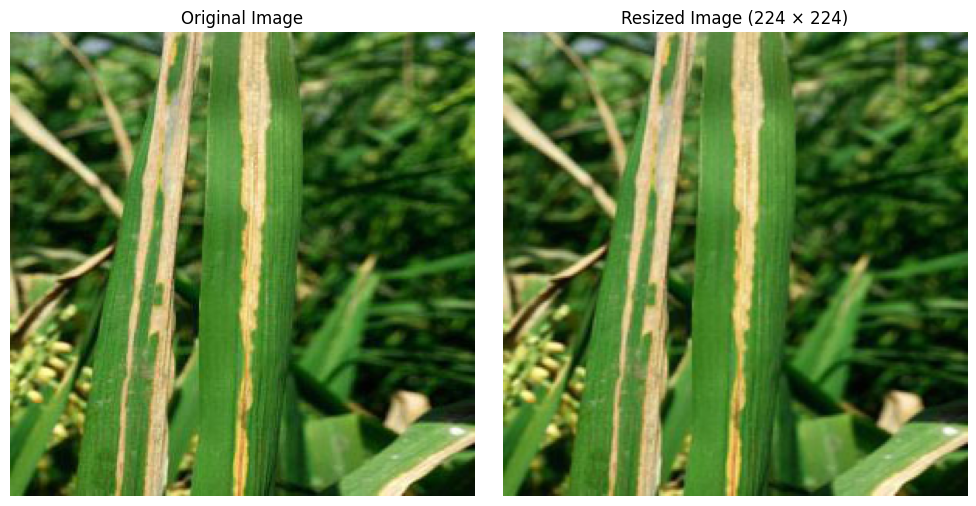

In [17]:
# Display original and resized images

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("Resized Image (224 × 224)")
plt.axis("off")

plt.tight_layout()
plt.show()

### Result

The sample image was successfully resized to **224 × 224 pixels** using
the LANCZOS resampling method.

The original and resized images are displayed above to demonstrate the
effect of the resizing process. Standardizing the image dimensions
provides a consistent input size for the subsequent machine learning
pipeline.

In [19]:
member01_eda_path = os.path.join(
    project_path,
    "Member 01_IT25103233",
    "EDA"
)

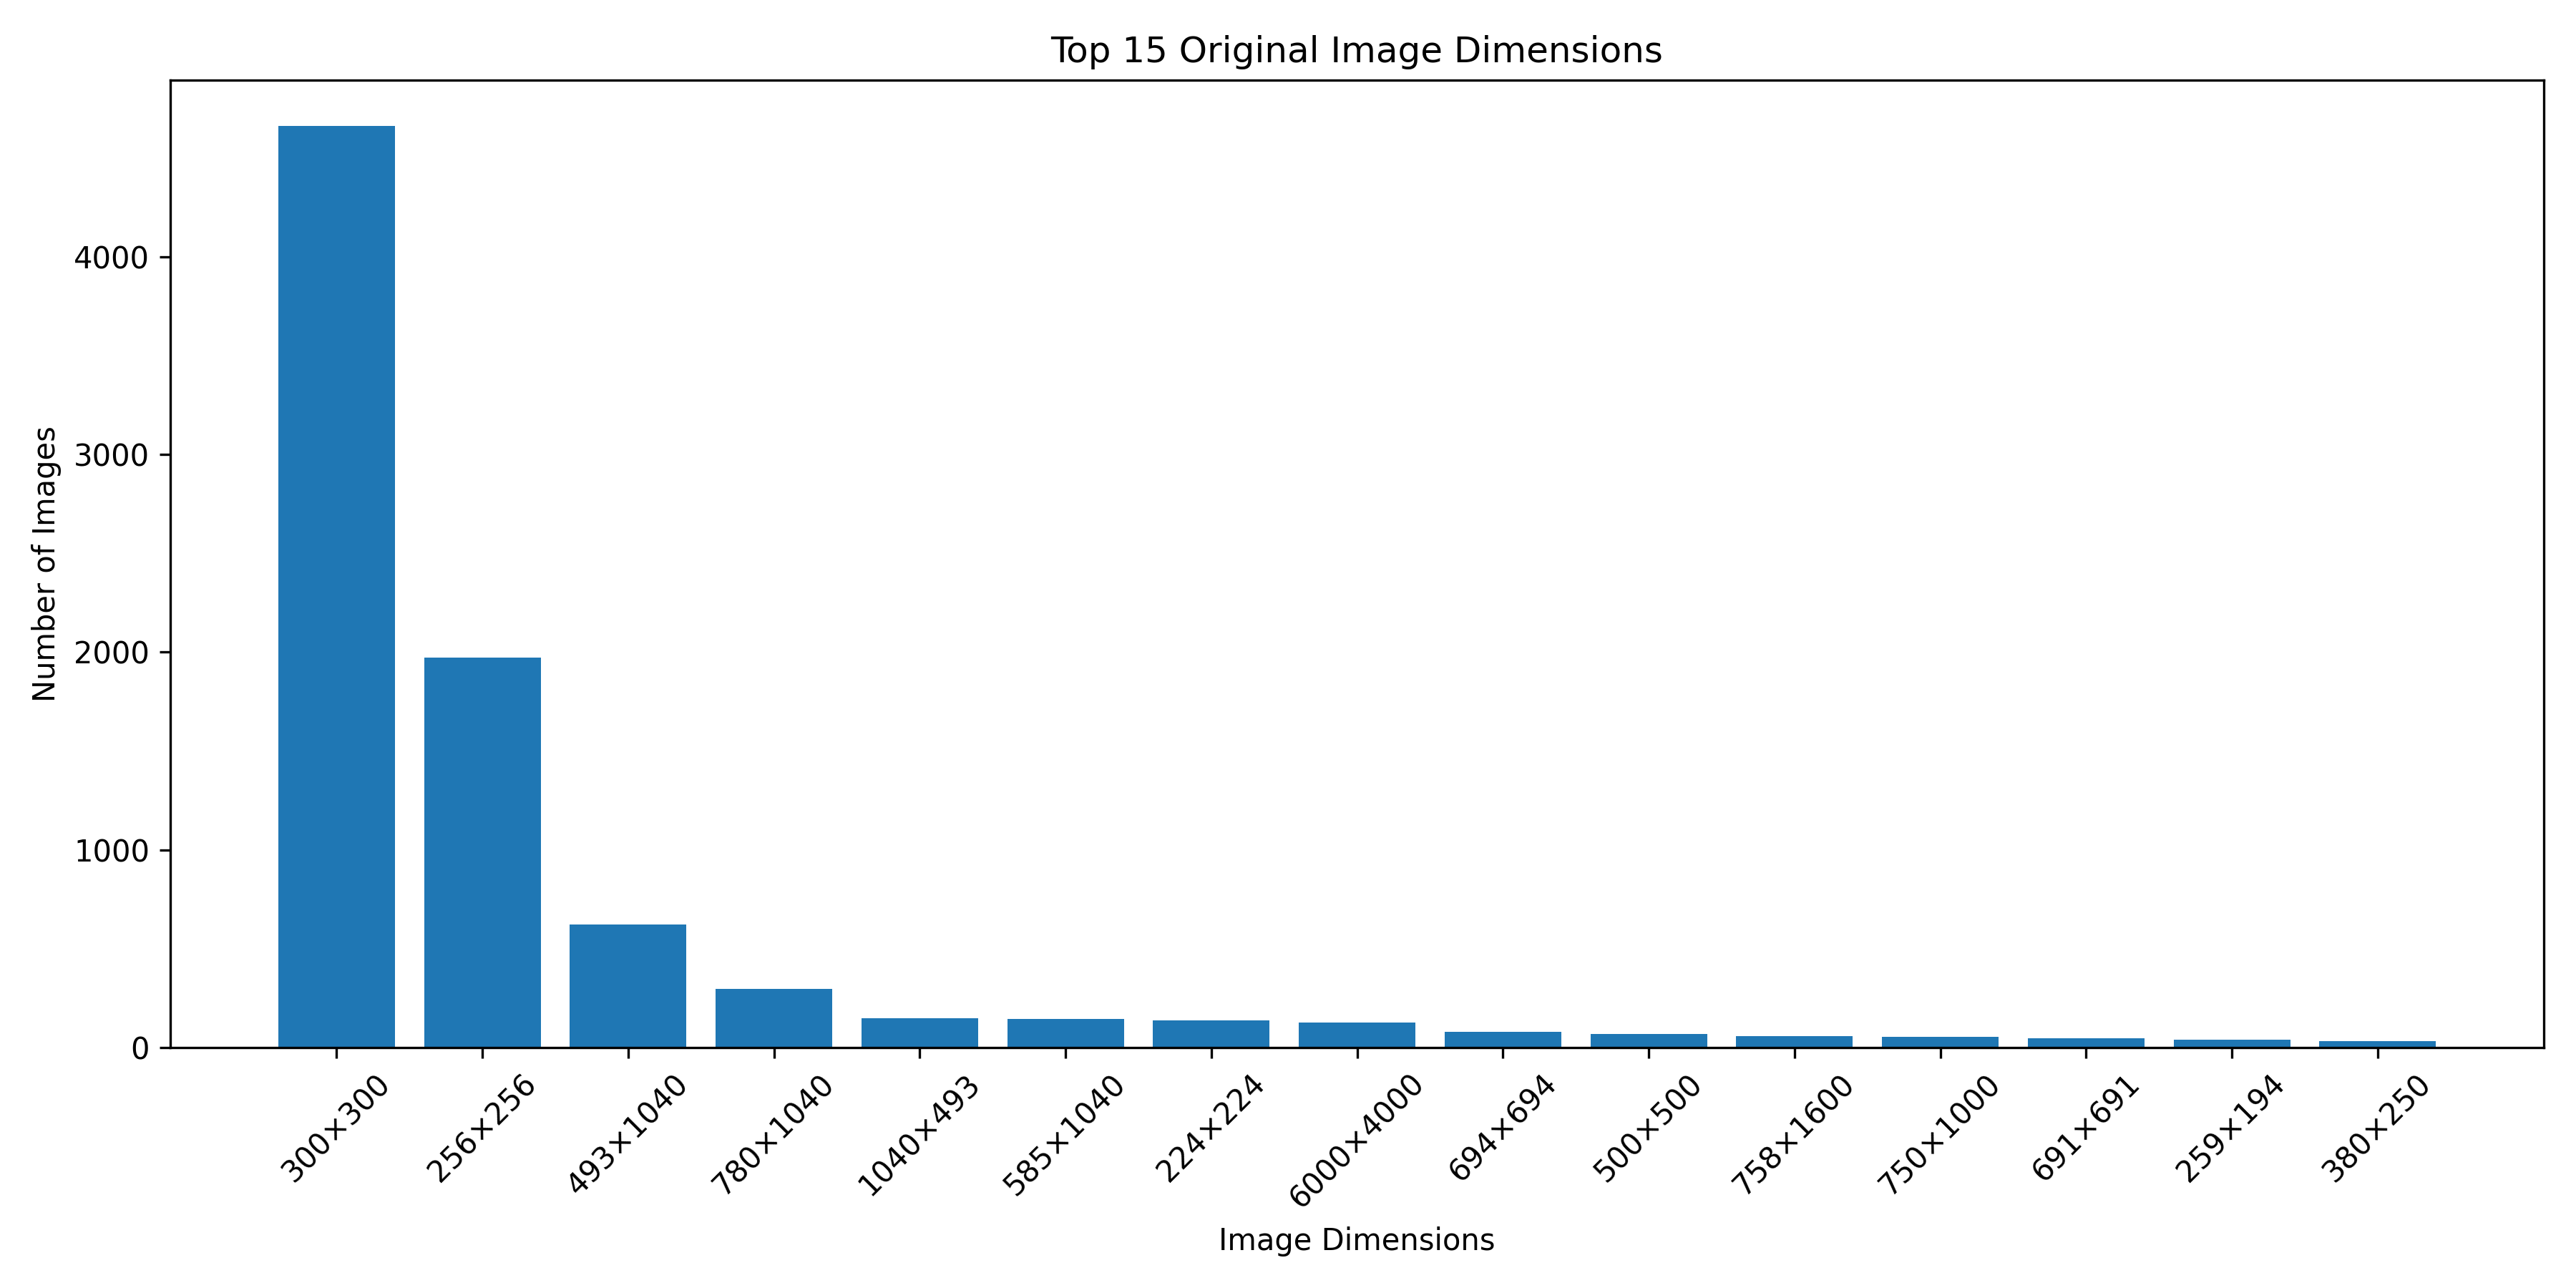

In [20]:
# Display Member 01 EDA - Original Image Dimensions

from IPython.display import display, Image as IPImage

original_dimensions_file = os.path.join(
    project_path,
    "Member 01_IT25103233",
    "EDA",
    "Original_Image_Dimensions.png"
)

display(IPImage(filename=original_dimensions_file))

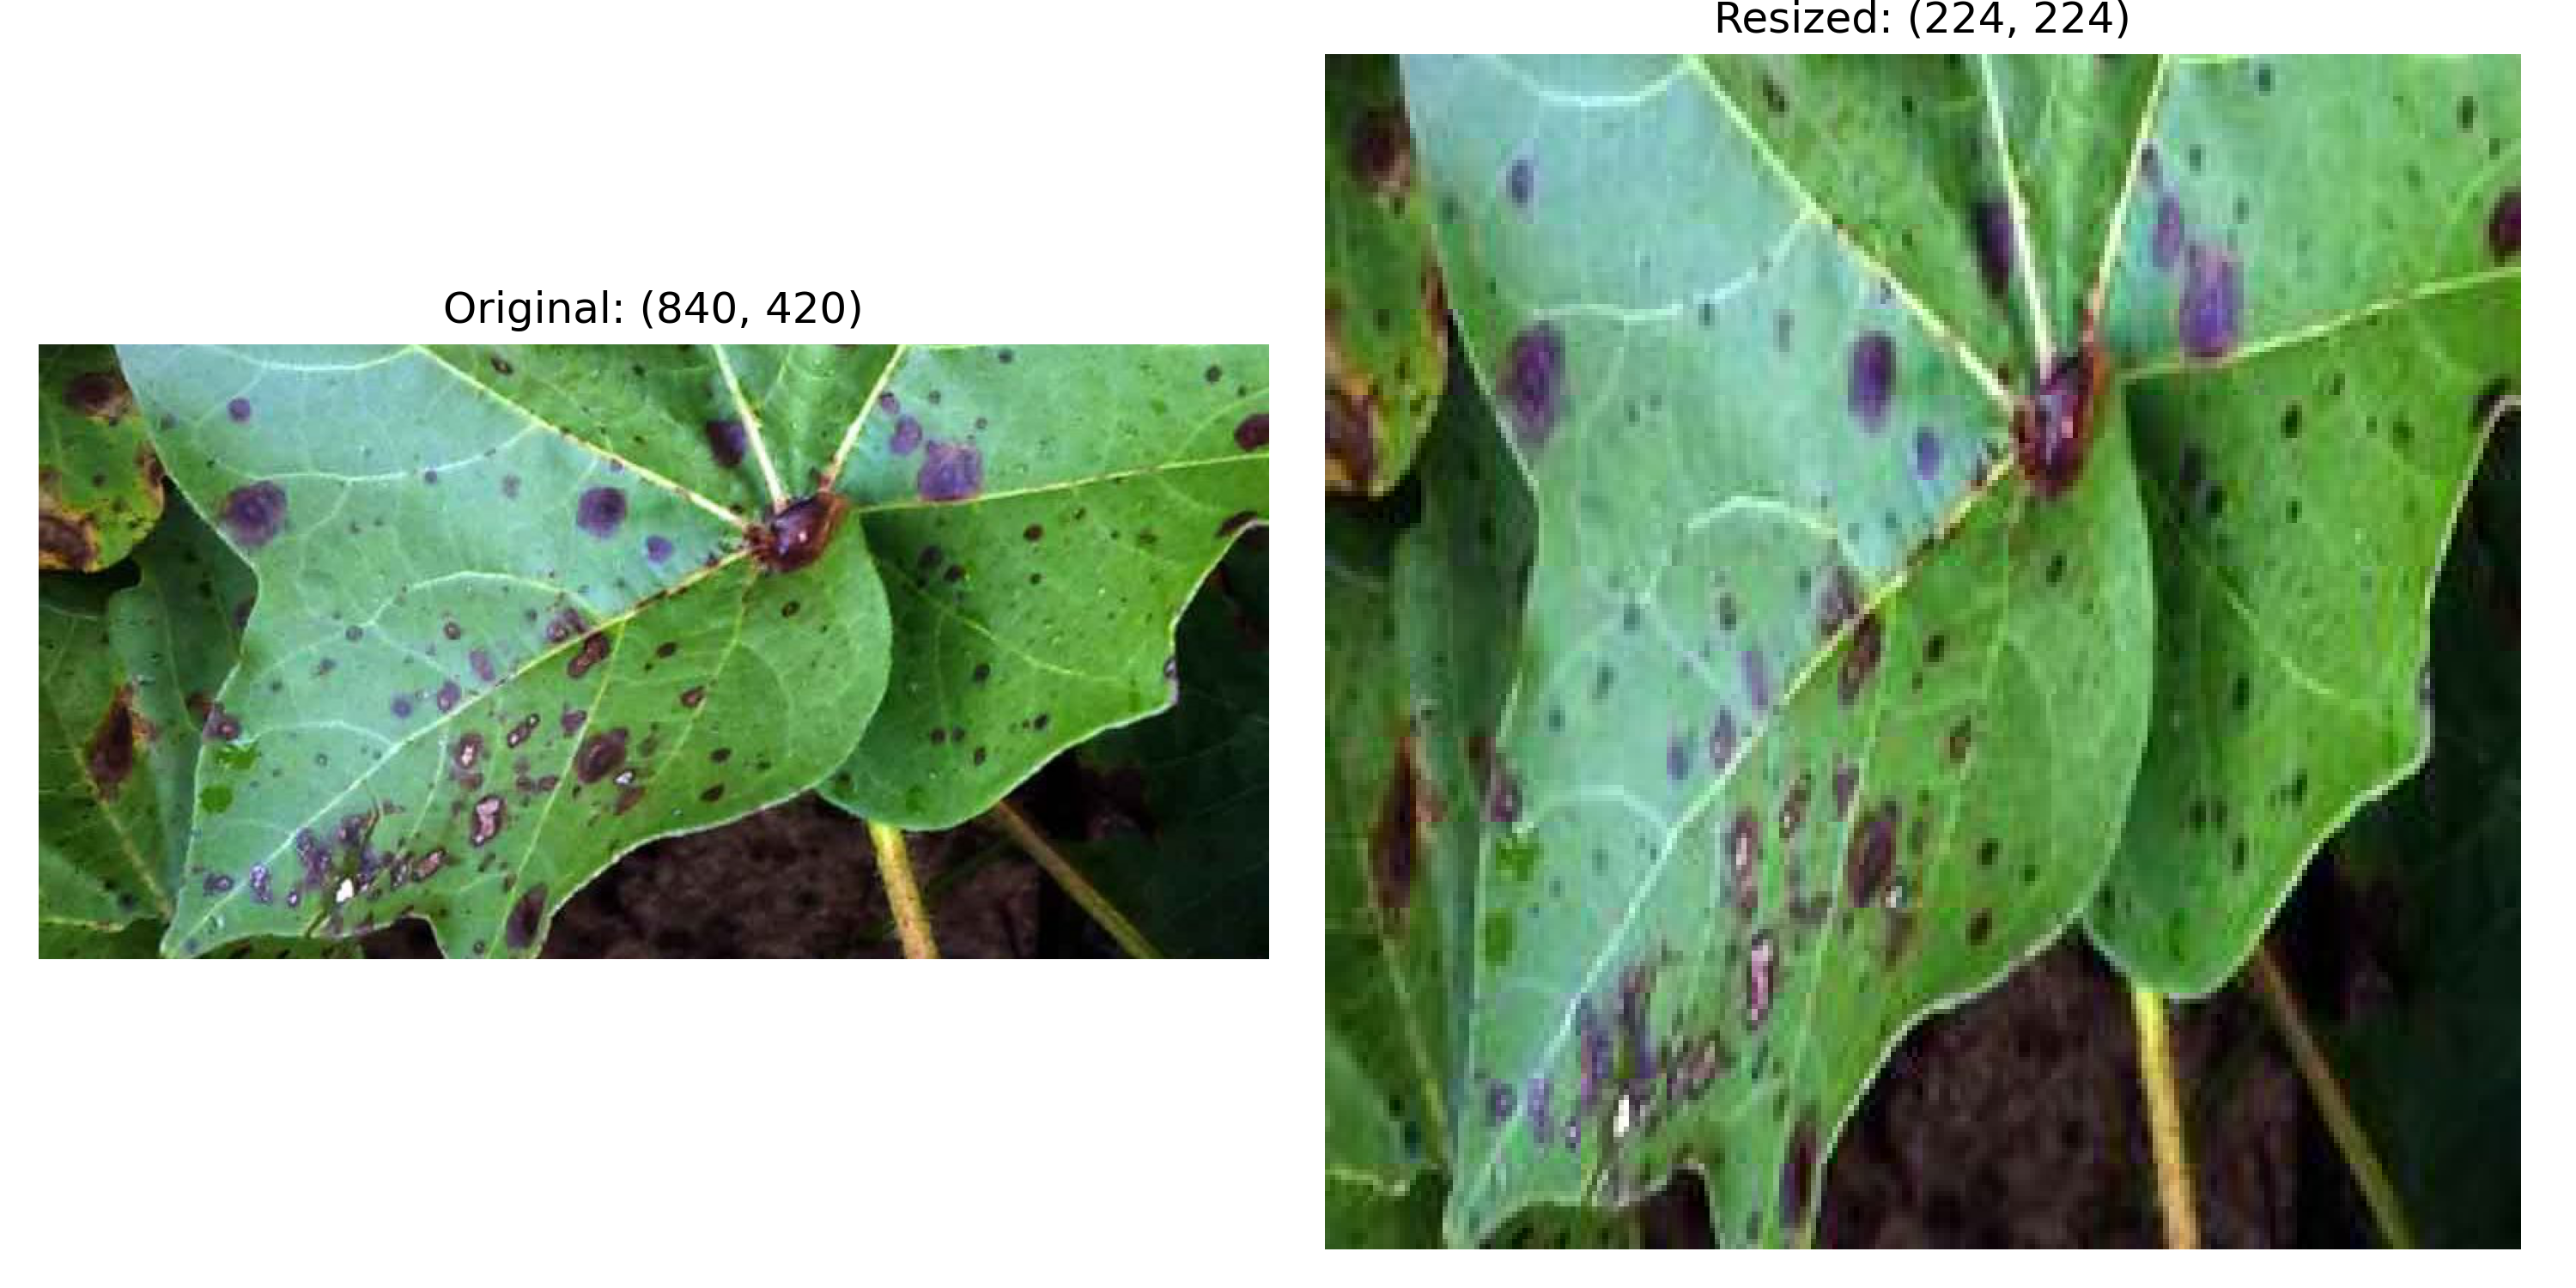

In [21]:
# Display Member 01 EDA - Original vs Resized

original_vs_resized_file = os.path.join(
    project_path,
    "Member 01_IT25103233",
    "EDA",
    "Original_vs_Resized.png"
)

display(IPImage(filename=original_vs_resized_file))

### EDA Interpretation

The original image dimensions visualization shows that the images in the
dataset have different dimensions.

The original versus resized visualization demonstrates that the images
were converted to a consistent **224 × 224 pixel** dimension.

This standardization ensures that the images have a uniform input size for
the subsequent stages of the machine learning pipeline.

## 5. Member 02 – Pixel Normalization

**Student ID:** IT25103229

### Brief Explanation

Pixel normalization is used to scale image pixel values from the original
range of **0–255** to a normalized range of **0–1**.

Member 02 applied pixel normalization to the resized training images.
The normalized images were then used as the input for the subsequent
preprocessing stages.

The normalization result is verified by examining the pixel-value range
before and after normalization.

In [22]:
# Member 02 - Pixel Normalization

# Convert pixel values from 0-255 to 0-1
normalized_image = np.array(resized_image) / 255.0

print("Original pixel value range: 0-255")
print("Normalized pixel value range:",
      normalized_image.min(),
      "to",
      normalized_image.max())

Original pixel value range: 0-255
Normalized pixel value range: 0.0 to 1.0


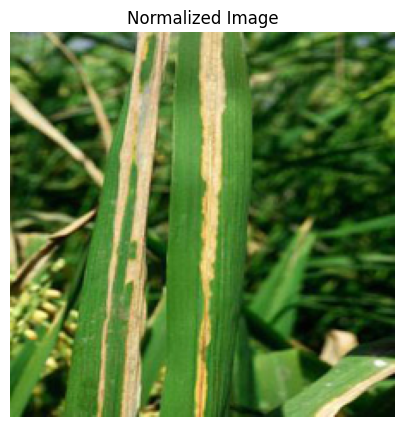

In [23]:
# Display the normalized image

plt.figure(figsize=(5, 5))

plt.imshow(normalized_image)
plt.title("Normalized Image")
plt.axis("off")

plt.show()

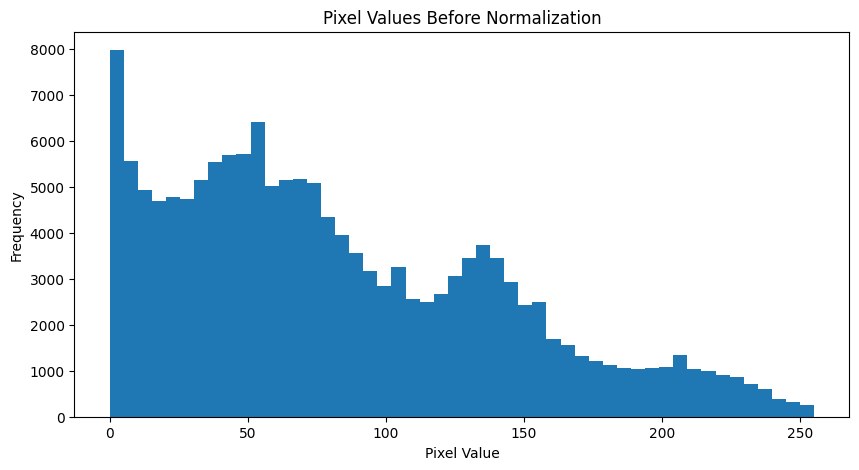

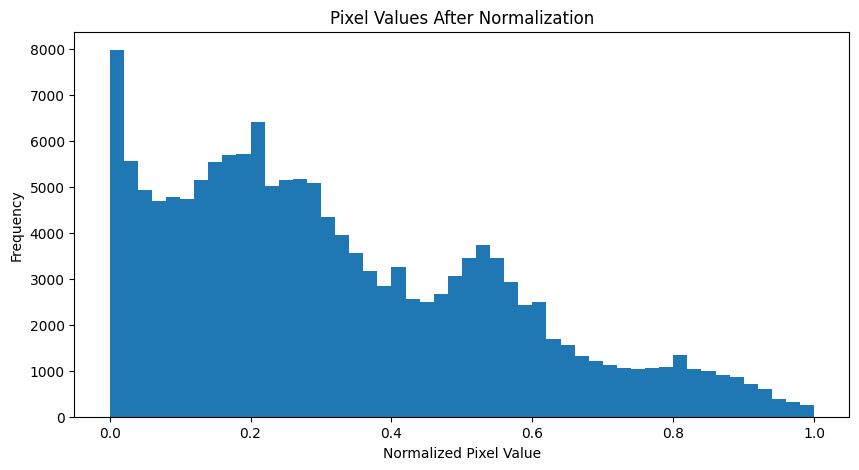

In [25]:
# Compare pixel-value distributions before and after normalization

# Convert the resized image to a NumPy array
image_array = np.array(resized_image)

# Normalize pixel values from 0-255 to 0-1
normalized_image = image_array / 255.0


# Pixel distribution before normalization
plt.figure(figsize=(10, 5))

plt.hist(
    image_array.flatten(),
    bins=50
)

plt.title("Pixel Values Before Normalization")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.show()


# Pixel distribution after normalization
plt.figure(figsize=(10, 5))

plt.hist(
    normalized_image.flatten(),
    bins=50
)

plt.title("Pixel Values After Normalization")
plt.xlabel("Normalized Pixel Value")
plt.ylabel("Frequency")

plt.show()

### Result

The pixel values were successfully converted from the original 0–255
range to the normalized 0–1 range.

The output confirms that the normalization process was successfully
applied to the image data.

### EDA Interpretation

The first histogram shows the distribution of pixel values before
normalization on the 0–255 scale.

The second histogram shows the same pixel distribution after conversion
to the 0–1 scale.

The distribution pattern is retained while the numerical range is
changed, confirming the effect of pixel normalization.

## 6. Member 03 – Data Augmentation

**Student ID:** IT25103371

### Brief Explanation

Data augmentation is used to increase the diversity of the training
dataset by applying transformations to existing images.

Member 03 applied targeted augmentation to minority classes in the training
dataset. The augmentation techniques included horizontal flipping, random
rotation, random zoom, and random translation.

The augmentation was applied only to the training data. The validation
dataset was not augmented.

A total of **3,160 additional augmented images** were generated for the
12 selected minority classes and stored separately from the original
dataset.

In [26]:
# Member 03 - Inspect Data Augmentation Outputs

member03_path = os.path.join(
    project_path,
    "Member 03_IT25103371"
)

print("Member 03 folder:", member03_path)

print("\nContents:")

for item in os.listdir(member03_path):
    print("-", item)

Member 03 folder: /content/drive/MyDrive/Group_AIML/Member 03_IT25103371

Contents:
- Notebook
- Outputs
- EDA


In [27]:
# Inspect Member 03 output folder

member03_output_path = os.path.join(
    member03_path,
    "Outputs"
)

print("Member 03 output files:")

for item in os.listdir(member03_output_path):
    print("-", item)

Member 03 output files:
- final_training_class_distribution.csv
- targeted_augmented_images
- augmentation_summary.csv
- augmentation_methodology.txt


In [28]:
# Member 03 - Count Augmented Samples

augmented_files = []

for root, dirs, files in os.walk(member03_output_path):
    for file in files:
        if file.lower().endswith(".npy"):
            augmented_files.append(
                os.path.join(root, file)
            )

print("Total augmented samples generated:", len(augmented_files))

Total augmented samples generated: 3160


Augmented file:
aug_0000.npy

Image shape: (224, 224, 3)
Pixel value range: 0.0 to 0.99964756


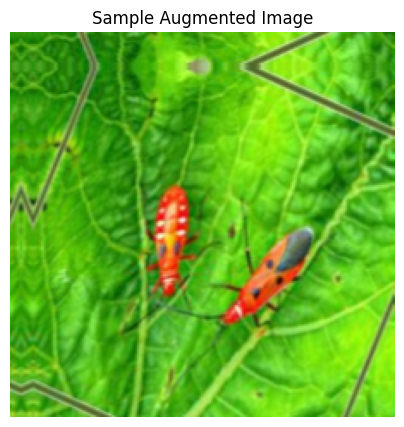

In [29]:
# Display one actual augmented image from Member 03

if len(augmented_files) > 0:

    sample_augmented_file = augmented_files[0]

    augmented_image = np.load(sample_augmented_file)

    print("Augmented file:")
    print(os.path.basename(sample_augmented_file))

    print("\nImage shape:", augmented_image.shape)
    print("Pixel value range:",
          augmented_image.min(),
          "to",
          augmented_image.max())

    plt.figure(figsize=(5, 5))

    plt.imshow(augmented_image)
    plt.title("Sample Augmented Image")
    plt.axis("off")

    plt.show()

else:
    print("No augmented .npy files were found.")

### EDA Visualization

The data augmentation EDA compares the class distribution before and
after targeted augmentation.

The visualization helps show how augmentation was applied to the selected
minority classes in the training dataset.

In [30]:
# Inspect Member 03 EDA files

member03_eda_path = os.path.join(
    member03_path,
    "EDA"
)

print("Member 03 EDA files:")

for item in os.listdir(member03_eda_path):
    print("-", item)

Member 03 EDA files:
- original_vs_augmented.png
- targeted_augmentation_plan.csv
- class_distribution_before_after_augmentation.png



EDA Visualization: original_vs_augmented.png


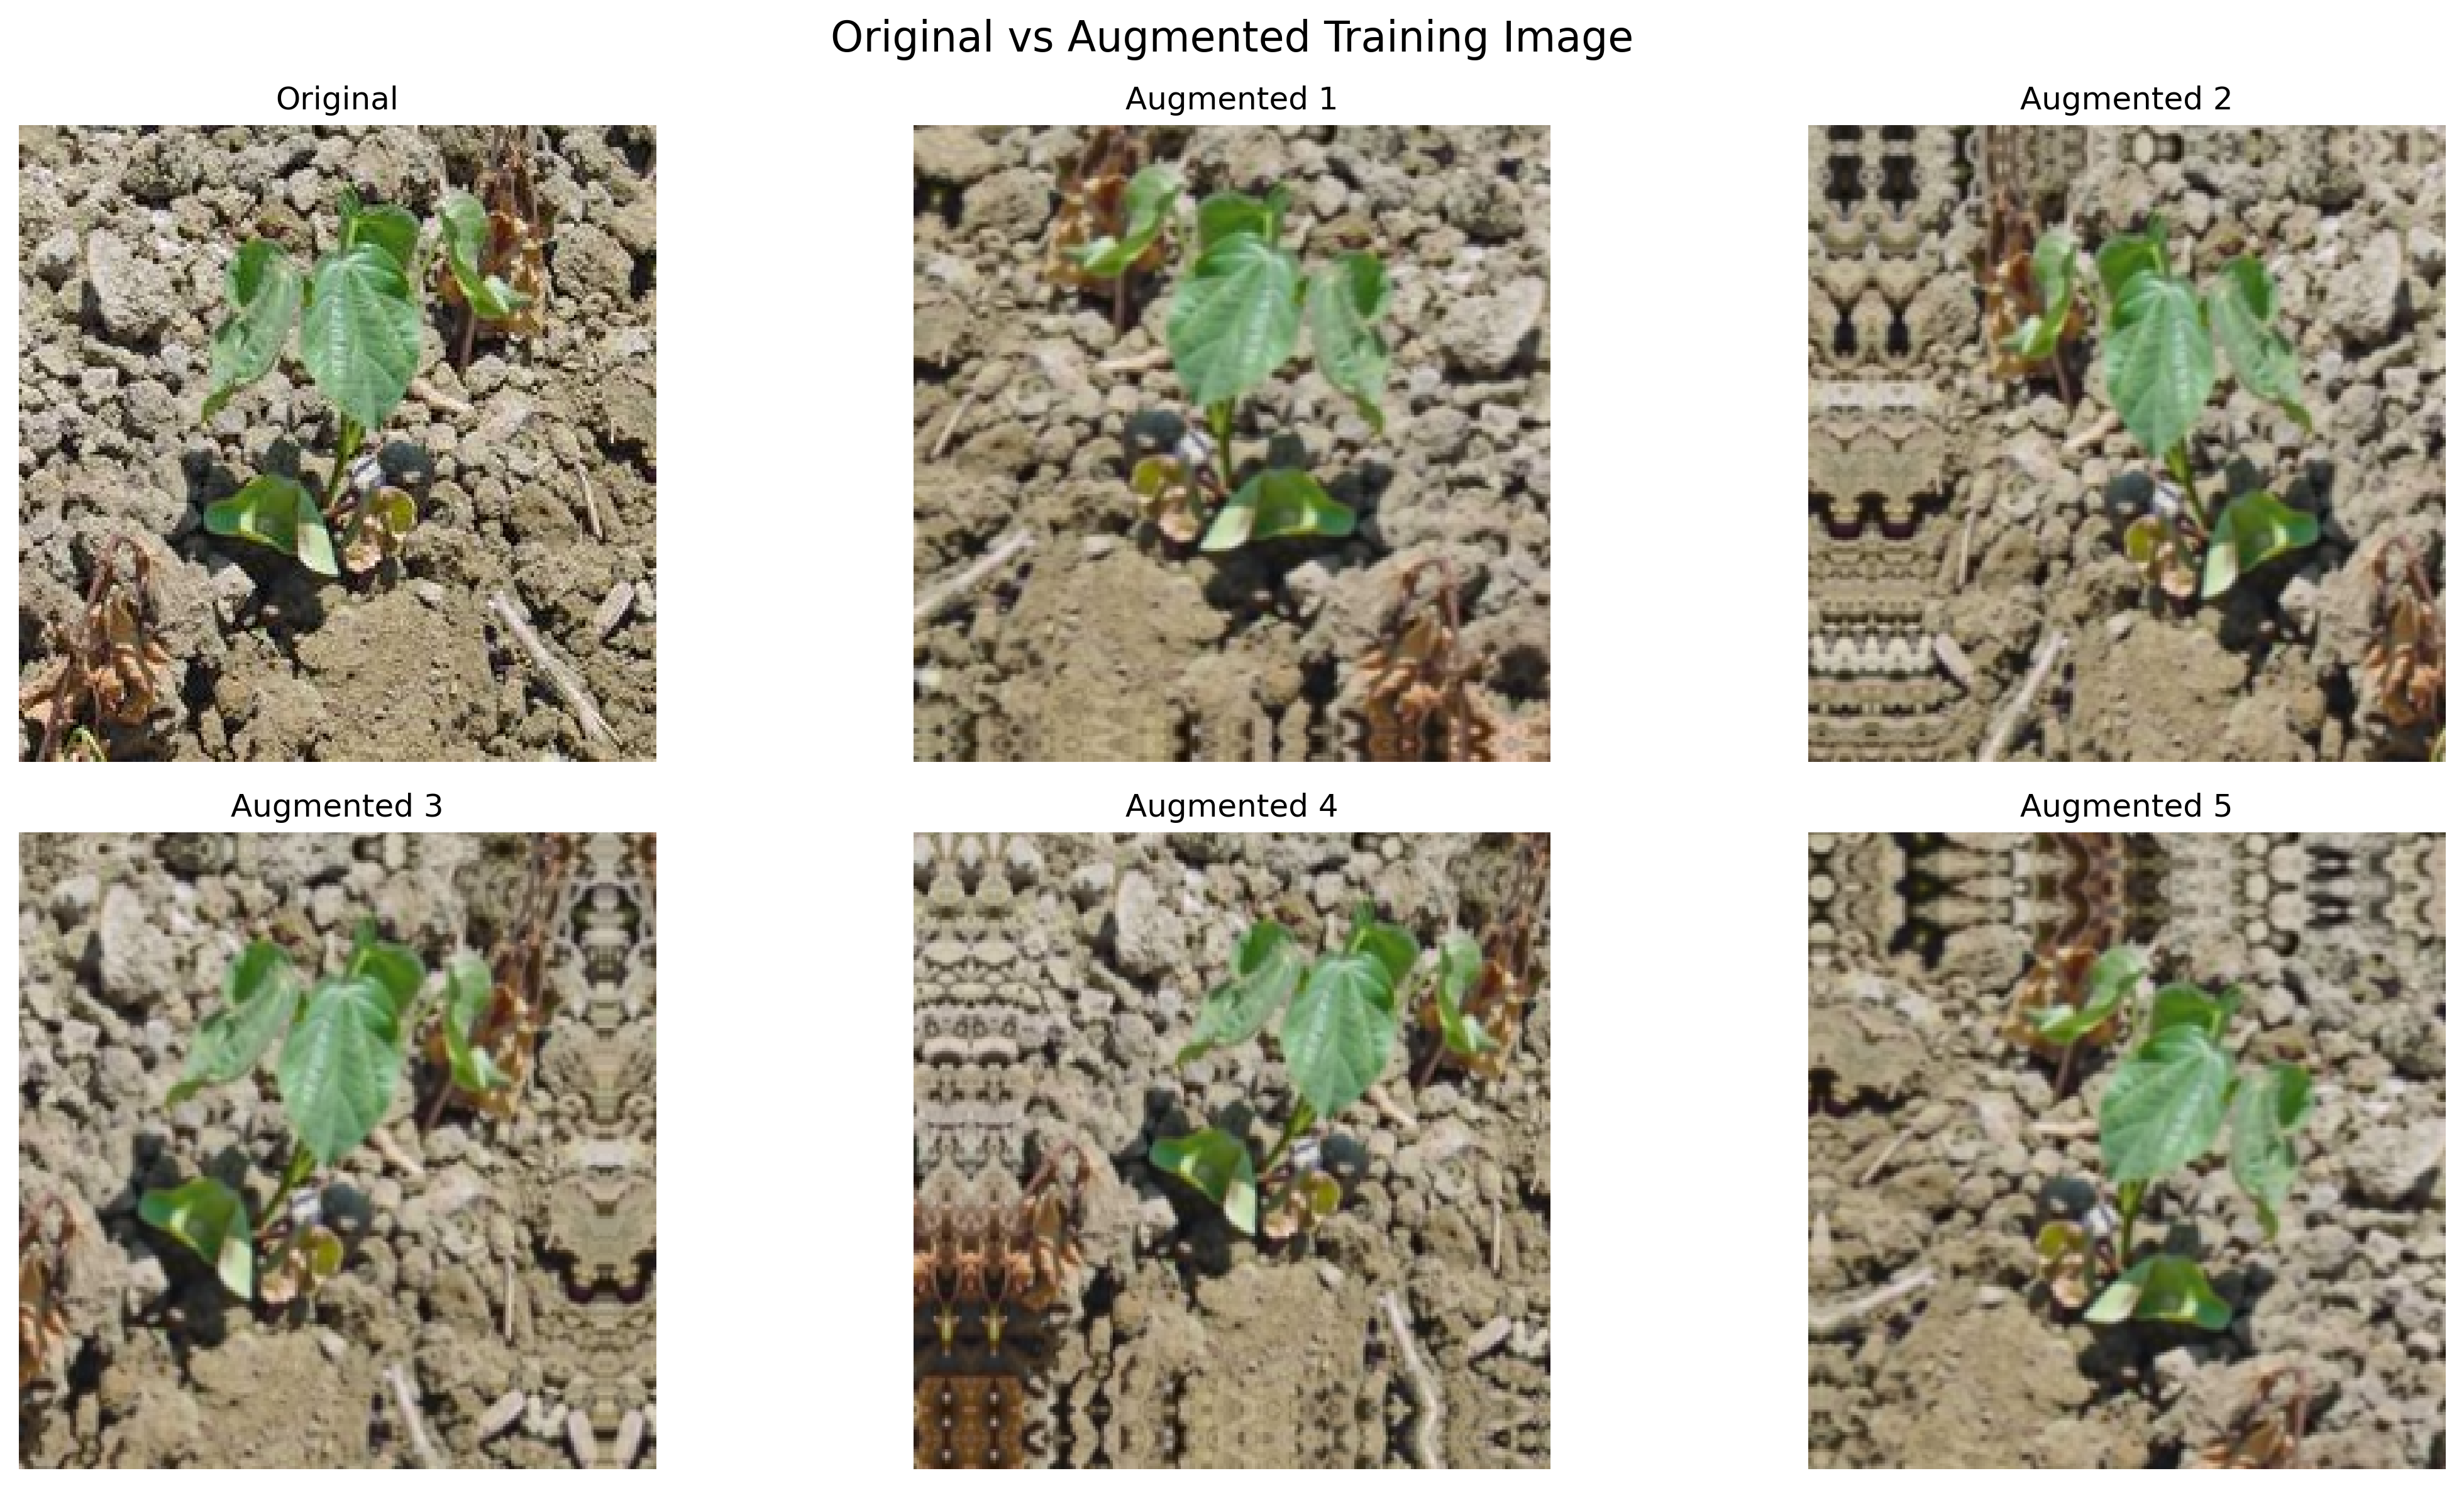


EDA Visualization: class_distribution_before_after_augmentation.png


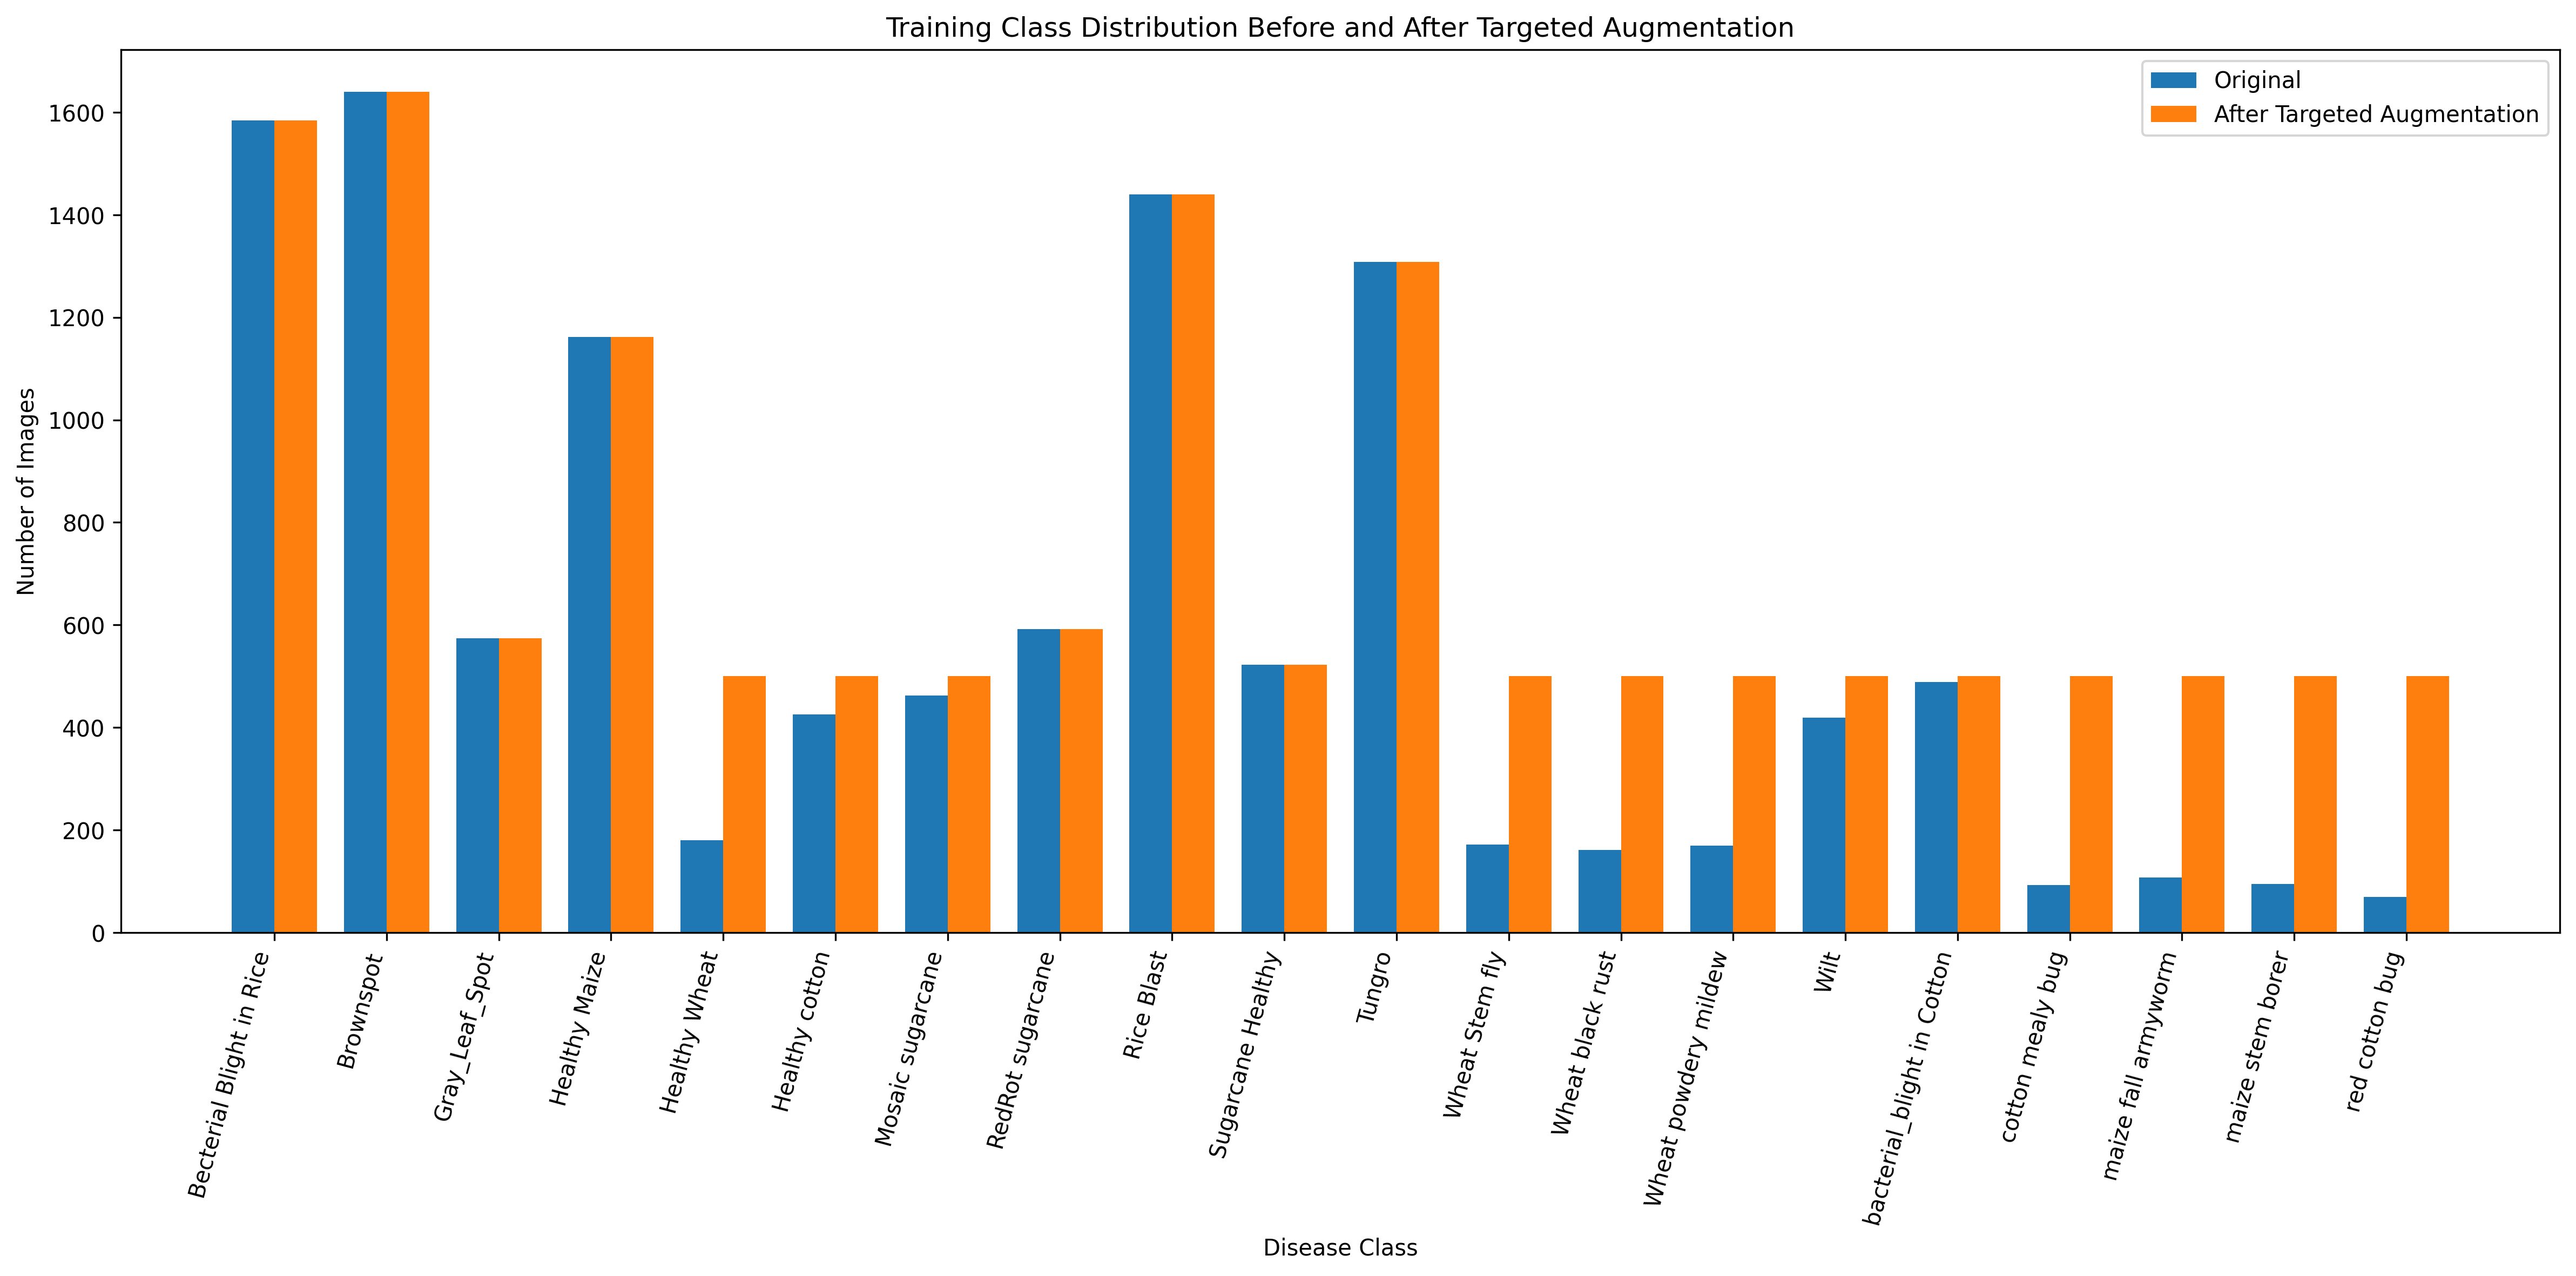

In [31]:
# Display Member 03 EDA visualizations

from IPython.display import display, Image as IPImage

for file in os.listdir(member03_eda_path):

    file_path = os.path.join(
        member03_eda_path,
        file
    )

    if file.lower().endswith((".png", ".jpg", ".jpeg")):

        print("\nEDA Visualization:", file)

        display(
            IPImage(filename=file_path)
        )

### Result and EDA Interpretation

Member 03 generated **3,160 additional augmented training samples** for
12 selected minority classes.

The augmentation process used horizontal flipping, random rotation, random
zoom, and random translation to increase the diversity of the selected
training classes.

The EDA visualization shows the distribution of the augmented samples
across the selected classes.

Validation images were not augmented, keeping the validation data
separate from the augmentation process.

## 7. Member 04 – Categorical Label Encoding

**Student ID:** IT25103567

### Brief Explanation

Categorical label encoding converts the categorical disease class names
into numerical labels that can be used by machine learning algorithms.

Member 04 applied the `LabelEncoder` technique to the 20 disease classes.
Each disease class was assigned a unique numerical label from 0 to 19.

The numerical labels are identifiers for the disease classes and do not
represent disease severity or ranking.

In [33]:
# Member 04 - Categorical Label Encoding

from sklearn.preprocessing import LabelEncoder

# Get all unique disease classes from Train and Validation
class_names = sorted(
    set(train_classes + validation_classes)
)

print("Number of disease classes:", len(class_names))
print("\nDisease classes:")

for class_name in class_names:
    print("-", class_name)


# Create the label encoder
label_encoder = LabelEncoder()

# Fit the encoder using all disease classes
label_encoder.fit(class_names)

print("\nLabel encoder created successfully.")
print("Number of encoded classes:", len(label_encoder.classes_))

Number of disease classes: 20

Disease classes:
- Becterial Blight in Rice
- Brownspot
- Gray_Leaf_Spot
- Healthy Maize
- Healthy Wheat
- Healthy cotton
- Mosaic sugarcane
- RedRot sugarcane
- Rice Blast
- Sugarcane Healthy
- Tungro
- Wheat Stem fly
- Wheat black rust
- Wheat powdery mildew
- Wilt
- bacterial_blight in Cotton
- cotton mealy bug
- maize fall armyworm
- maize stem borer
- red cotton bug

Label encoder created successfully.
Number of encoded classes: 20


In [34]:
# Generate the class-to-label mapping

label_mapping = pd.DataFrame({
    "Disease Class": label_encoder.classes_,
    "Encoded Label": label_encoder.transform(label_encoder.classes_)
})

print("Categorical Label Encoding Result")
print("----------------------------------")

display(label_mapping)

Categorical Label Encoding Result
----------------------------------


,Disease Class,Encoded Label
0,Becterial Blight in Rice,0
1,Brownspot,1
2,Gray_Leaf_Spot,2
3,Healthy Maize,3
4,Healthy Wheat,4
5,Healthy cotton,5
6,Mosaic sugarcane,6
7,RedRot sugarcane,7
8,Rice Blast,8
9,Sugarcane Healthy,9


In [36]:
# Save the label mapping

label_mapping_file = os.path.join(
    pipeline_path,
    "label_mapping.csv"
)

label_mapping.to_csv(
    label_mapping_file,
    index=False
)

print("Label mapping saved successfully.")
print("Saved to:", label_mapping_file)

Label mapping saved successfully.
Saved to: /content/drive/MyDrive/Group_AIML/02_Group_Pipeline/label_mapping.csv


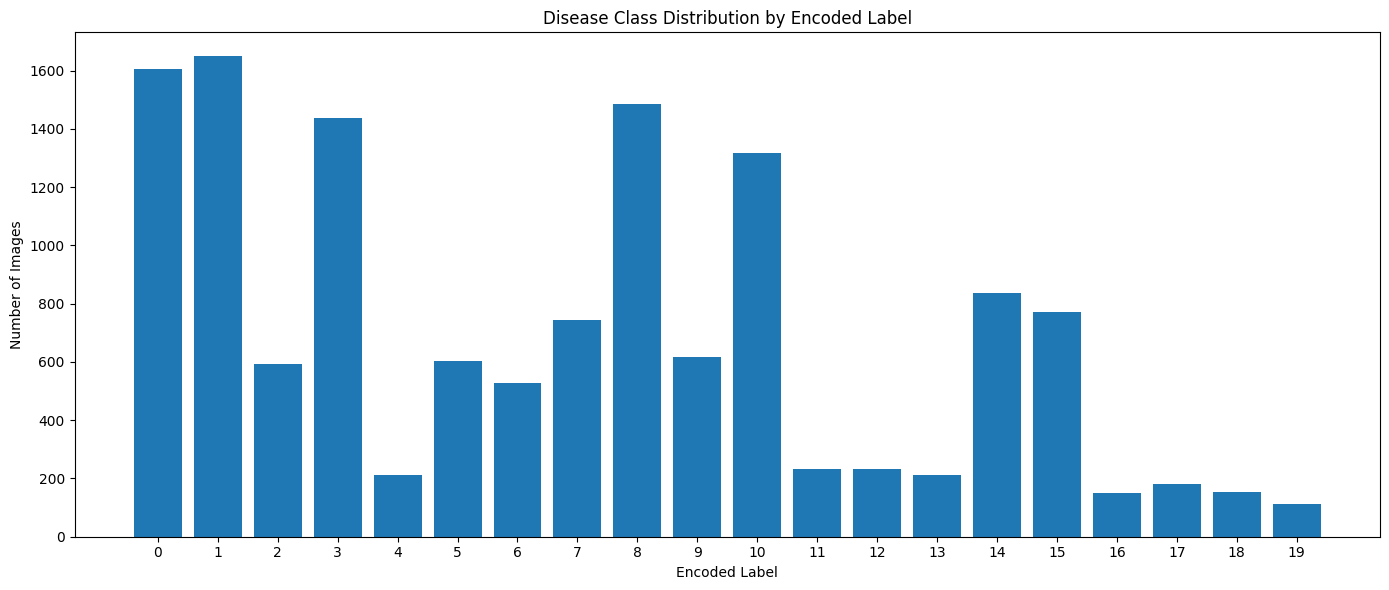

In [37]:
# EDA 1 - Encoded Label Distribution

# Create class distribution using the encoded labels
encoded_distribution = pd.DataFrame({
    "Encoded Label": label_encoder.transform(class_names),
    "Disease Class": class_names,
    "Image Count": [
        train_counts.get(class_name, 0) +
        validation_counts.get(class_name, 0)
        for class_name in class_names
    ]
})

# Sort according to encoded label
encoded_distribution = encoded_distribution.sort_values(
    "Encoded Label"
)

plt.figure(figsize=(14, 6))

plt.bar(
    encoded_distribution["Encoded Label"],
    encoded_distribution["Image Count"]
)

plt.xlabel("Encoded Label")
plt.ylabel("Number of Images")
plt.title("Disease Class Distribution by Encoded Label")

plt.xticks(
    encoded_distribution["Encoded Label"]
)

plt.tight_layout()
plt.show()

### EDA Interpretation

The first EDA visualization shows the distribution of the 20 disease
classes using their encoded labels from 0 to 19.


The results confirm that each disease class has been assigned a unique
numerical identifier. Label encoding changes the representation of the
categorical class names into numerical values without changing the class
membership.

## 8. Member 05 – Class Imbalance Handling

**Student ID:** IT25103052

### Brief Explanation

Class imbalance occurs when some disease classes contain substantially
fewer images than other classes.

Member 05 investigated the class distribution of the training dataset
to identify underrepresented disease classes.

The imbalance was addressed by applying targeted augmentation to selected
minority classes so that their representation in the training dataset
could be improved.

The class distribution was compared before and after the imbalance
handling process.

In [38]:
# Member 05 - Class Imbalance Handling

# Use the training class distribution before imbalance handling
class_imbalance_before = pd.DataFrame({
    "Disease Class": list(train_counts.keys()),
    "Image Count": list(train_counts.values())
})

# Sort by image count
class_imbalance_before = class_imbalance_before.sort_values(
    "Image Count"
)

print("Training class distribution before imbalance handling:")
display(class_imbalance_before)

print(
    "\nNumber of training classes:",
    len(class_imbalance_before)
)

print(
    "Smallest class:",
    class_imbalance_before.iloc[0]["Disease Class"],
    "->",
    class_imbalance_before.iloc[0]["Image Count"],
    "images"
)

print(
    "Largest class:",
    class_imbalance_before.iloc[-1]["Disease Class"],
    "->",
    class_imbalance_before.iloc[-1]["Image Count"],
    "images"
)

Training class distribution before imbalance handling:


,Disease Class,Image Count
19,red cotton bug,69
16,cotton mealy bug,92
18,maize stem borer,95
17,maize fall armyworm,107
12,Wheat black rust,161
13,Wheat powdery mildew,169
11,Wheat Stem fly,172
4,Healthy Wheat,180
14,Wilt,419
5,Healthy cotton,426



Number of training classes: 20
Smallest class: red cotton bug -> 69 images
Largest class: Brownspot -> 1640 images


In [39]:
# Member 05 - Inspect Class Imbalance Handling Outputs

member05_path = os.path.join(
    project_path,
    "Member 05_IT25103052"
)

print("Member 05 folder:", member05_path)

print("\nContents:")

for item in os.listdir(member05_path):
    print("-", repr(item))

Member 05 folder: /content/drive/MyDrive/Group_AIML/Member 05_IT25103052

Contents:
- 'Notebook'
- 'EDA'
- 'Outputs'


In [40]:
# Member 05 - Inspect the Outputs folder

member05_output_path = os.path.join(
    member05_path,
    "Outputs"
)

print("Member 05 Outputs folder:")
print(member05_output_path)

print("\nOutput files:")

for item in os.listdir(member05_output_path):
    print("-", repr(item))

Member 05 Outputs folder:
/content/drive/MyDrive/Group_AIML/Member 05_IT25103052/Outputs

Output files:
- 'class_distribution.csv'
- 'class_weights.csv'


In [41]:
# Member 05 - Load the class distribution

class_distribution_file = os.path.join(
    member05_output_path,
    "class_distribution.csv"
)

class_distribution = pd.read_csv(
    class_distribution_file
)

print("Class Distribution:")
display(class_distribution)

Class Distribution:


,Class,Original_Count,Augmented_Count,Final_Count
0,Brownspot,1640,0,1640
1,Becterial Blight in Rice,1584,0,1584
2,Rice Blast,1440,0,1440
3,Tungro,1308,0,1308
4,Healthy Maize,1162,0,1162
5,RedRot sugarcane,592,0,592
6,Gray_Leaf_Spot,574,0,574
7,Sugarcane Healthy,522,0,522
8,bacterial_blight in Cotton,489,11,500
9,Mosaic sugarcane,462,38,500


In [42]:
# Member 05 - Load the class weights

class_weights_file = os.path.join(
    member05_output_path,
    "class_weights.csv"
)

class_weights = pd.read_csv(
    class_weights_file
)

print("Class Weights:")
display(class_weights)

Class Weights:


,Class Name,Encoded Label,Class,Final_Count,Class_Weight
0,Becterial Blight in Rice,0,Becterial Blight in Rice,1584,0.467866
1,Brownspot,1,Brownspot,1640,0.451890
2,Gray_Leaf_Spot,2,Gray_Leaf_Spot,574,1.291115
3,Healthy Maize,3,Healthy Maize,1162,0.637780
4,Healthy Wheat,4,Healthy Wheat,500,1.482200
5,Healthy cotton,5,Healthy cotton,500,1.482200
6,Mosaic sugarcane,6,Mosaic sugarcane,500,1.482200
7,RedRot sugarcane,7,RedRot sugarcane,592,1.251858
8,Rice Blast,8,Rice Blast,1440,0.514653
9,Sugarcane Healthy,9,Sugarcane Healthy,522,1.419732


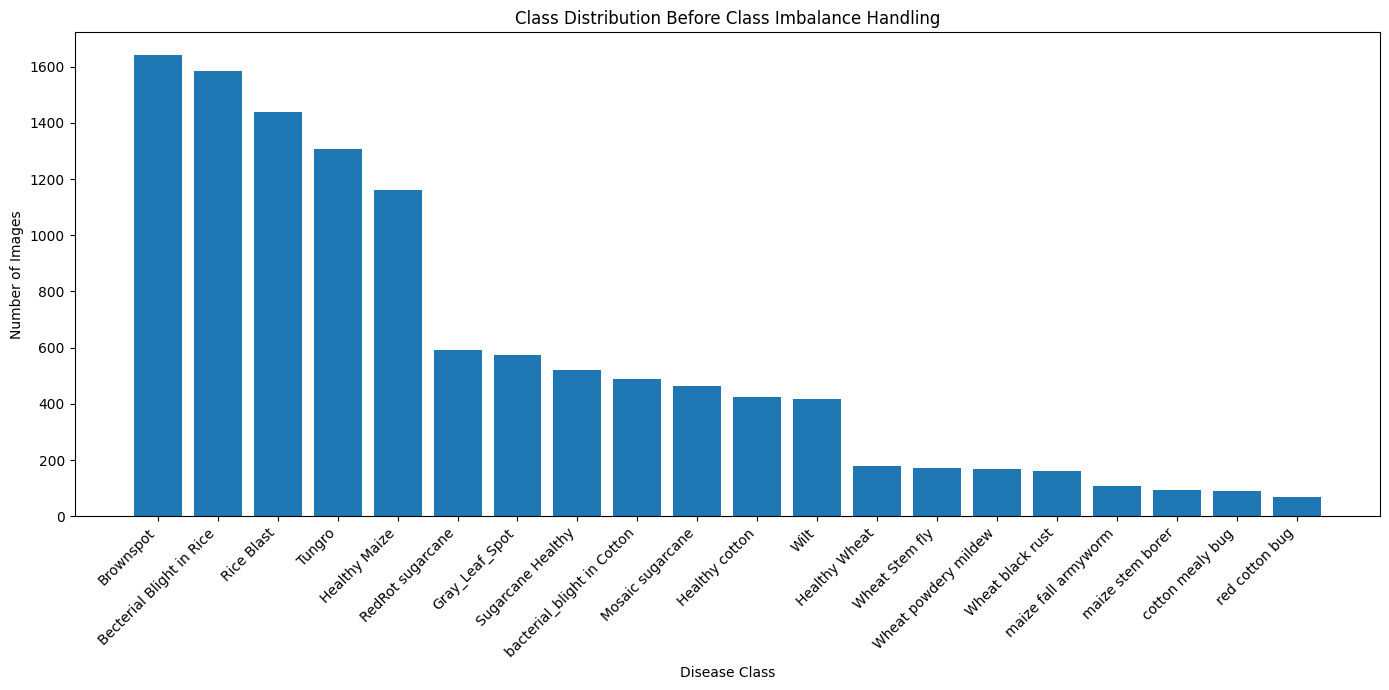

In [43]:
# Member 05 - EDA: Class Distribution

plt.figure(figsize=(14, 7))

plt.bar(
    class_distribution.iloc[:, 0],
    class_distribution.iloc[:, 1]
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution Before Class Imbalance Handling")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

### EDA Interpretation

The class distribution visualization shows that the training dataset is
imbalanced, with some disease classes containing substantially more images
than others.

The class weights calculated by Member 05 provide higher weights to
underrepresented classes and lower weights to classes with larger
representation.

This analysis identifies the class imbalance in the training dataset and
shows how class weights can be used to address the imbalance during model
training.

### Result

Member 05 successfully identified the class imbalance in the training
dataset.

The class distribution was saved as `class_distribution.csv`, and the
calculated class weights were saved as `class_weights.csv`.

These outputs can be used in the subsequent model-training stage to give
appropriate importance to the different disease classes.

## 9. Member 06 – Image Color/Channel Preprocessing

**Student ID:** IT25103274

### Brief Explanation

Image color/channel preprocessing ensures that all images use a consistent
color representation and number of channels.

Member 06 investigated the image channels in the dataset and ensured that
images are represented consistently in RGB format.

This preprocessing is important because machine learning models require
images with a consistent channel structure as input.

In [44]:
# Member 06 - Image Color/Channel Preprocessing

# Use the sample image from the previous preprocessing section
sample_array = np.array(original_image)

print("Original image mode:", original_image.mode)
print("Image shape:", sample_array.shape)

if len(sample_array.shape) == 3:
    print("Number of channels:", sample_array.shape[2])
else:
    print("Number of channels: 1")

# Convert the image to RGB
rgb_image = original_image.convert("RGB")
rgb_array = np.array(rgb_image)

print("\nAfter RGB conversion:")
print("Image mode:", rgb_image.mode)
print("Image shape:", rgb_array.shape)
print("Number of channels:", rgb_array.shape[2])

Original image mode: RGB
Image shape: (300, 300, 3)
Number of channels: 3

After RGB conversion:
Image mode: RGB
Image shape: (300, 300, 3)
Number of channels: 3


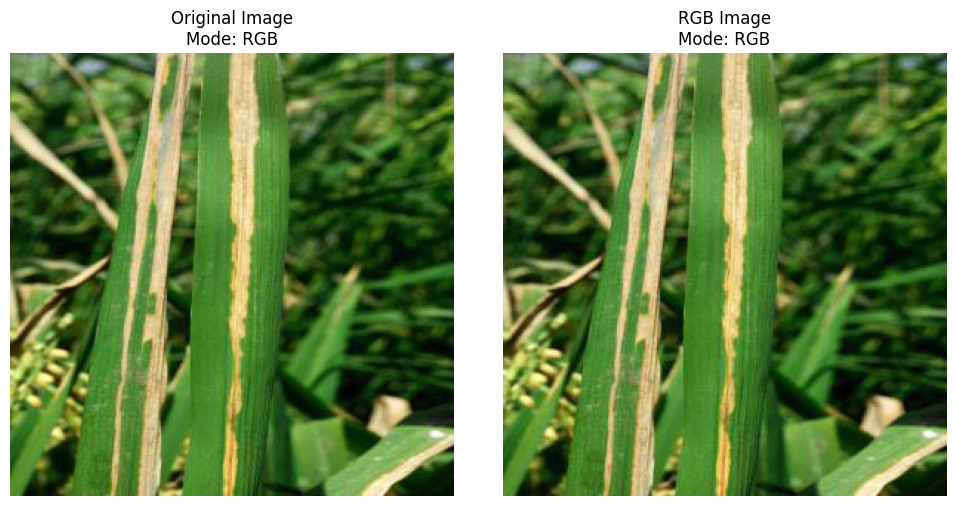

In [45]:
# Member 06 - EDA: Image Channel Comparison

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nMode: {original_image.mode}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_image)
plt.title(f"RGB Image\nMode: {rgb_image.mode}")
plt.axis("off")

plt.tight_layout()
plt.show()

### EDA Interpretation

The visualization compares the sample image before and after conversion
to RGB format.

The image is represented using a consistent three-channel RGB structure
after preprocessing.

This ensures that the image data has a consistent channel format for the
subsequent stages of the machine learning pipeline.

### Result

The image channel structure was successfully checked and standardized
to RGB format.

The preprocessing ensures that images contain three consistent color
channels, providing a uniform image representation for the subsequent
machine learning stages.

## 10. Member 07 – Image Quality Enhancement

**Student ID:** IT25103599

### Brief Explanation

Image quality enhancement is used to improve the visual quality of images
when issues such as poor contrast or noise may affect the image data.

Member 07 investigated the image quality of the crop disease dataset and
applied appropriate enhancement techniques where required.

The preprocessing aims to improve image quality while preserving the
important visual features used for disease classification.

In [46]:
# Member 07 - Image Quality Enhancement

from PIL import ImageEnhance

# Use the sample image from the dataset
quality_image = original_image.convert("RGB")

# Enhance image contrast
contrast_enhancer = ImageEnhance.Contrast(quality_image)

enhanced_image = contrast_enhancer.enhance(1.2)

print("Original image mode:", quality_image.mode)
print("Enhanced image mode:", enhanced_image.mode)
print("Contrast enhancement factor:", 1.2)

Original image mode: RGB
Enhanced image mode: RGB
Contrast enhancement factor: 1.2


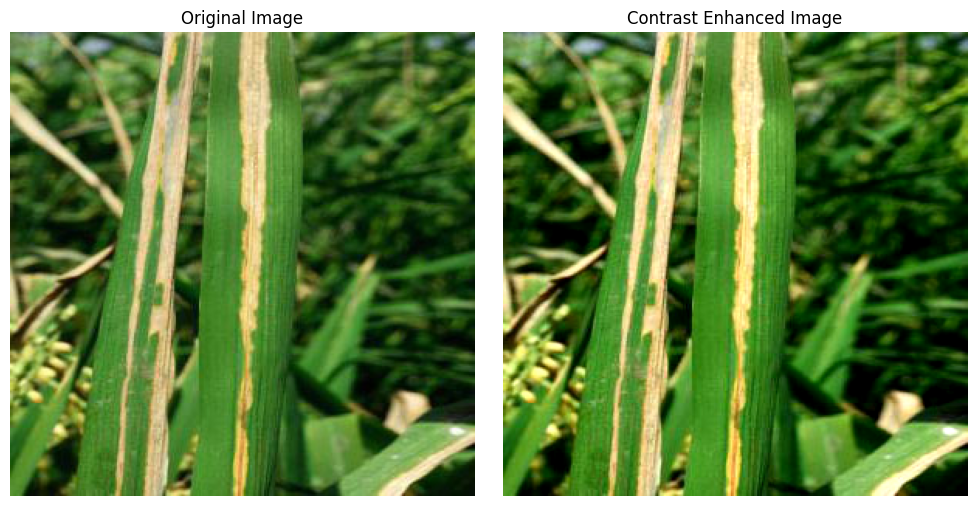

In [47]:
# Member 07 - EDA: Before and After Image Quality Enhancement

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(quality_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image)
plt.title("Contrast Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### EDA Interpretation

The visualization compares the original image with the contrast-enhanced
image.

The enhanced image shows an increase in contrast while preserving the
main visual characteristics of the original image.

This demonstrates how image quality enhancement can improve the visual
representation of the image before the subsequent machine learning stages.

### Result

The image quality enhancement process was successfully demonstrated using
contrast enhancement.

The comparison shows the effect of the enhancement on the sample image
while maintaining its main visual characteristics.

The enhanced image can be used as part of the preprocessing workflow for
the subsequent machine learning stages.

## 11. Final Preprocessed Dataset

The seven preprocessing techniques were integrated into the group
preprocessing workflow in the following order:

**Raw Dataset**
→ **Image Resizing**
→ **Pixel Normalization**
→ **Data Augmentation**
→ **Categorical Label Encoding**
→ **Class Imbalance Handling**
→ **Image Color/Channel Preprocessing**
→ **Image Quality Enhancement**
→ **Final Preprocessed Dataset**

Each preprocessing technique was completed by its assigned group member.
The corresponding preprocessing outputs and EDA visualizations are stored
in the respective member folders.

The final preprocessed dataset will be used in the subsequent machine
learning stages.

## 12. Preprocessing Summary

The Crop Disease dataset was processed using the seven preprocessing
techniques completed by the group members.

| Step | Preprocessing Technique | Main Purpose |
|------|--------------------------|--------------|
| 1 | Image Resizing | Standardize image dimensions |
| 2 | Pixel Normalization | Scale pixel values from 0–255 to 0–1 |
| 3 | Data Augmentation | Increase training data diversity |
| 4 | Categorical Label Encoding | Convert disease names into numerical labels |
| 5 | Class Imbalance Handling | Address differences in class representation |
| 6 | Image Color/Channel Preprocessing | Ensure consistent image channels |
| 7 | Image Quality Enhancement | Improve image quality where required |

The preprocessing outputs and EDA visualizations generated by the
individual members provide the basis for the subsequent machine learning
pipeline.

In [49]:
# Final Preprocessing Results Verification

print("=" * 60)
print("FINAL PREPROCESSING RESULTS")
print("=" * 60)


# 1. Image Resizing
print("\n1. Image Resizing")
print("-----------------")

print("Original image size :", original_image.size)
print("Resized image size  :", resized_image.size)
print("Target size         :", target_size)


# 2. Pixel Normalization
print("\n2. Pixel Normalization")
print("----------------------")

print(
    "Original pixel range :",
    image_array.min(),
    "to",
    image_array.max()
)

print(
    "Normalized range     :",
    normalized_image.min(),
    "to",
    normalized_image.max()
)


# 3. Data Augmentation
print("\n3. Data Augmentation")
print("--------------------")

print(
    "Additional augmented images :",
    len(augmented_files)
)

# Find the class folders containing the augmented files
augmented_class_names = sorted(
    set(
        os.path.basename(os.path.dirname(file))
        for file in augmented_files
    )
)

print(
    "Augmented classes           :",
    len(augmented_class_names)
)


# 4. Categorical Label Encoding
print("\n4. Categorical Label Encoding")
print("-----------------------------")

encoded_class_labels = label_encoder.transform(
    label_encoder.classes_
)

print(
    "Number of disease classes :",
    len(label_encoder.classes_)
)

print(
    "Encoded label range      :",
    encoded_class_labels.min(),
    "to",
    encoded_class_labels.max()
)


# 5. Class Imbalance Handling
print("\n5. Class Imbalance Handling")
print("---------------------------")

print(
    "Number of classes analyzed :",
    len(class_distribution)
)

print(
    "Class weights generated    :",
    len(class_weights)
)


# 6. Image Color/Channel Preprocessing
print("\n6. Image Color/Channel Preprocessing")
print("------------------------------------")

print(
    "Image mode before :",
    original_image.mode
)

print(
    "Image mode after  :",
    rgb_image.mode
)

print(
    "Number of channels:",
    rgb_array.shape[2]
)


# 7. Image Quality Enhancement
print("\n7. Image Quality Enhancement")
print("----------------------------")

print(
    "Original image size  :",
    quality_image.size
)

print(
    "Enhanced image size  :",
    enhanced_image.size
)

print(
    "Contrast enhancement factor:",
    1.2
)


print("\n" + "=" * 60)
print("FINAL PREPROCESSING VERIFICATION COMPLETED")
print("=" * 60)

FINAL PREPROCESSING RESULTS

1. Image Resizing
-----------------
Original image size : (300, 300)
Resized image size  : (224, 224)
Target size         : (224, 224)

2. Pixel Normalization
----------------------
Original pixel range : 0 to 255
Normalized range     : 0.0 to 1.0

3. Data Augmentation
--------------------
Additional augmented images : 3160
Augmented classes           : 12

4. Categorical Label Encoding
-----------------------------
Number of disease classes : 20
Encoded label range      : 0 to 19

5. Class Imbalance Handling
---------------------------
Number of classes analyzed : 20
Class weights generated    : 20

6. Image Color/Channel Preprocessing
------------------------------------
Image mode before : RGB
Image mode after  : RGB
Number of channels: 3

7. Image Quality Enhancement
----------------------------
Original image size  : (300, 300)
Enhanced image size  : (300, 300)
Contrast enhancement factor: 1.2

FINAL PREPROCESSING VERIFICATION COMPLETED


## Conclusion

The data preprocessing stage of the Crop Disease AI project was
successfully completed by integrating the contributions of all seven
group members.

The dataset was processed through image resizing, pixel normalization,
data augmentation, categorical label encoding, class imbalance handling,
image color/channel preprocessing, and image quality enhancement.

The results and EDA visualizations demonstrate the effect of the applied
preprocessing techniques and provide a consistent dataset representation
for the subsequent machine learning stages.

The completed preprocessing pipeline provides a structured foundation for
developing and evaluating the crop disease classification model.